# 01 – Data exploration

What the raw inputs look like before they become a knowledge graph, and where they are weak.

| Source | Content |
|---|---|
| Wiener Linien GTFS (data.gv.at) | stations, trips, route variants, shapes |
| Willhaben listing sample | ~100 rental listings: position, rent, size |
| Stadt Wien district borders | 23 polygons with official area |

*Requires the raw GTFS feed in `data/raw/gtfs/` (see `data/README.md`).*

In [1]:
import sys, warnings, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root (notebooks live in kg/notebooks/)
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from kg.build_kg import load_inputs
inputs = load_inputs()   # parses ~6 M stop_times rows, takes ~30 s

## 1. Transit network

GTFS lists *platforms*; we merge them into **stations** (shared ID prefix) and collapse the
705 GTFS route variants into the **lines** passengers know (U6, 18, 13A).

stations total: 1,785   inside Vienna: 1,746
lines per mode:
bus          120
night bus     35
tram          29
subway         5
rail           1


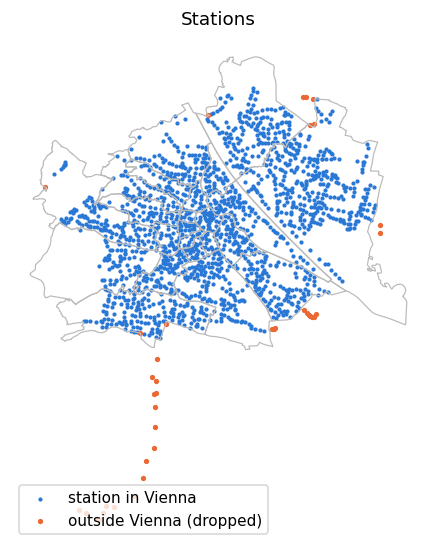

In [3]:
stations = inputs.stations
print(f"stations total: {len(stations):,}   inside Vienna: {stations['district'].notna().sum():,}")
modes = pd.Series(inputs.line_modes).value_counts()
print("lines per mode:"); print(modes.to_string())

fig, ax = plt.subplots(figsize=(7, 6))
districts = inputs.districts
districts.boundary.plot(ax=ax, color="#bbb", linewidth=0.8)
inside = stations.dropna(subset=["district"])
ax.scatter(inside["lon"], inside["lat"], s=3, color="#2a78d6", label="station in Vienna")
outside = stations[stations["district"].isna()]
ax.scatter(outside["lon"], outside["lat"], s=6, color="#eb6834", label="outside Vienna (dropped)")
ax.set_title("Stations"); ax.legend(loc="lower left"); ax.axis("off"); plt.show()

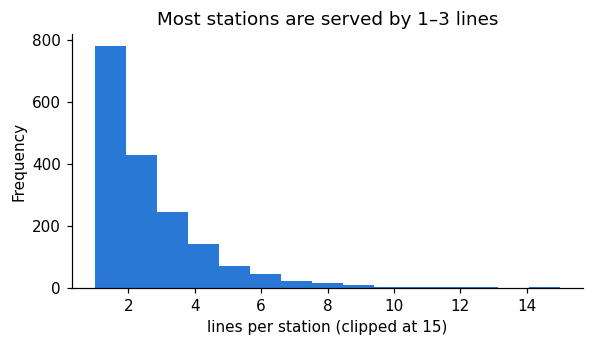

In [4]:
lines_per_station = inputs.station_lines.groupby("station_id").size()
ax = lines_per_station.clip(upper=15).plot.hist(bins=15, color="#2a78d6", figsize=(6, 3))
ax.set_xlabel("lines per station (clipped at 15)"); ax.set_title("Most stations are served by 1–3 lines"); plt.show()

## 2. Housing sample

The listings were copied from four result pages of a Willhaben search **sorted by price,
ascending** – so this is the cheapest end of the market on one day, not a representative sample.
`scripts/extract_listings.py` already removed garages, parking spots and short-term rentals;
the parser additionally drops listings < 10 m² or outside 3–60 €/m².

listings after cleaning: 102  (in Vienna: 101)


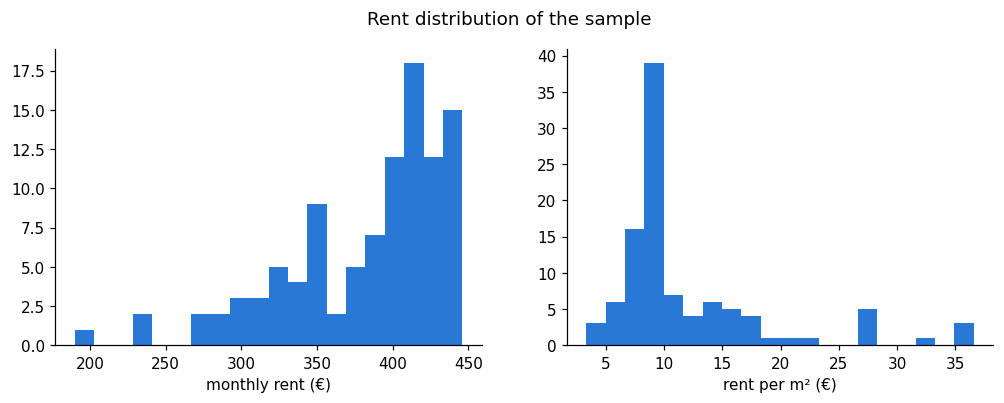

type
Wohnung                   65
Zimmer/WG                 18
Genossenschaftswohnung     6
Dachgeschoßwohnung         5
Erdgeschoßwohnung          4
Sonstige                   2
Garconniere                2
Name: count, dtype: int64

In [5]:
h = inputs.housing
print(f"listings after cleaning: {len(h)}  (in Vienna: {h['district'].notna().sum()})")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(h["price"], bins=20, color="#2a78d6"); axes[0].set_xlabel("monthly rent (€)")
axes[1].hist(h["price_per_sqm"], bins=20, color="#2a78d6"); axes[1].set_xlabel("rent per m² (€)")
fig.suptitle("Rent distribution of the sample"); plt.show()
h["type"].value_counts()

## 3. Coverage per district

Rent statistics need at least 3 listings per district (`MIN_LISTINGS_PER_DISTRICT`); below that the
district is reported as *no data* and treated as "average" in the match score.

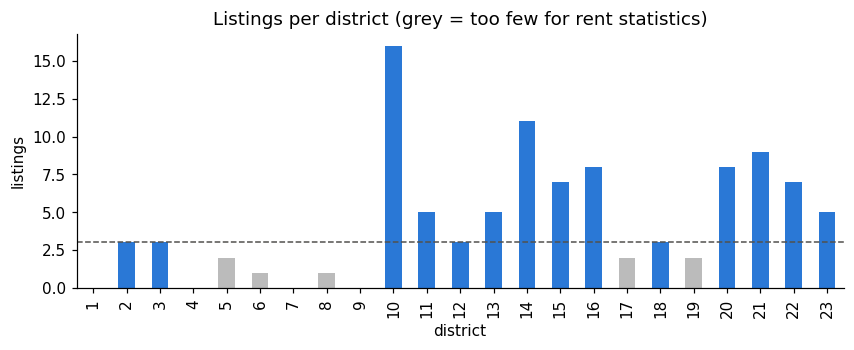

,area_km2,station_count,line_count,listing_count,median_rent,median_rent_per_sqm
district,,,,,,
1,2.868772,38,42,0,NaN,NaN
2,19.241996,85,22,3,420.000,9.130
3,7.403036,65,16,3,390.000,9.770
4,1.776322,17,13,0,NaN,NaN
5,2.011808,25,14,2,NaN,NaN
6,1.455044,13,11,1,NaN,NaN
7,1.608246,20,15,0,NaN,NaN
8,1.089946,13,13,1,NaN,NaN
9,2.967383,26,22,0,NaN,NaN


In [6]:
agg = inputs.aggregates
ax = agg["listing_count"].plot.bar(color=["#2a78d6" if n >= 3 else "#bbb" for n in agg["listing_count"]], figsize=(9, 3))
ax.axhline(3, color="#52514e", linestyle="--", linewidth=1); ax.set_xlabel("district"); ax.set_ylabel("listings")
ax.set_title("Listings per district (grey = too few for rent statistics)"); plt.show()
agg

## Take-aways

* The transit data is complete and rich: ~1,750 stations and ~190 lines inside Vienna.
* The housing sample is small and biased towards cheap listings, so rent is used only as a
  *relative* signal and missing districts are made explicit instead of being filled with 0.